# A5. 추론: prefill과 decode, KV 캐시, test-time scaling

- 영상: [52:30 Inference: prefill, decode & KV cache](https://www.youtube.com/watch?v=Vr1NzH8bT44&t=3150s), [59:56 Reasoning models & test-time scaling](https://www.youtube.com/watch?v=Vr1NzH8bT44&t=3596s) ~ 1:04:58
- 슬라이드: `data/lecture02.pdf` 119–148쪽 [1]

## 목표

1. GPU가 **계산**과 **메모리 읽기**를 어떻게 나눠 쓰는지 숫자로 보고, roofline 그림에 실제 측정값을 찍어 봅니다.
2. 프롬프트를 한꺼번에 읽는 **prefill**과 한 토큰씩 쓰는 **decode**의 속도 차이를 잽니다.
3. GPT-2에 **KV 캐시**를 직접 붙이고, 캐시가 있어도 결과가 같은지 확인합니다. 캐시가 메모리를 얼마나 먹는지 계산합니다.
4. **speculative decoding**(작은 모델이 먼저 쓰고 큰 모델이 검사)을 짜고, 큰 모델 혼자 쓴 결과와 똑같은지 확인합니다.
5. 답을 여러 번 뽑아 다수결/검증하는 방법과, 생각(thinking) 켜기의 효과를 잽니다.

**이 노트북이 답하는 질문**: 왜 긴 답을 쓰는 것이 긴 글을 읽는 것보다 훨씬 느리고, 추론 때 계산을 더 쓰면 무엇을 얻나?

문장 끝의 `[번호]`는 맨 아래 **출처** 절의 번호입니다. "이 노트북의 결과"라고 적은 것은 여기서 직접 돌린 실험 결과입니다.

In [1]:
# 그림 도구: 펼치지 않아도 됩니다.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "axes.spines.top": False, "axes.spines.right": False})
OI = {"orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "yellow": "#F0E442",
      "blue": "#0072B2", "red": "#D55E00", "pink": "#CC79A7", "black": "#000000", "grey": "#BBBBBB"}   # Okabe-Ito


def _box(ax, x, y, w, h, text, color, fs=9.5, tc="black", ec="#555555"):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=color, ec=ec, lw=1))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=tc)


def _arrow(ax, x0, y0, x1, y1, text=None, fs=8.5):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color="#444444", lw=1.3))
    if text:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.1, text, ha="center", va="bottom", fontsize=fs, color="#444444")


def flow(steps, notes=None, colors=None, ncol=4, title=None, w=2.3, h=0.9, figw=13):
    """steps 를 ncol 개씩 뱀 모양(다음 줄은 오른쪽에서 왼쪽)으로 상자-화살표로 그린다."""
    n = len(steps)
    nrow = (n + ncol - 1) // ncol
    fig, ax = plt.subplots(figsize=(figw, 1.75 * nrow + 0.3))
    pos = []
    for i in range(n):
        r, c = divmod(i, ncol)
        c = c if r % 2 == 0 else ncol - 1 - c
        pos.append((c * 3.2, -r * 1.75))
    for i, ((x, y), s) in enumerate(zip(pos, steps)):
        _box(ax, x, y, w, h, s, colors[i] if colors else OI["sky"])
        if notes and notes[i]:
            ax.text(x, y - h / 2 - 0.08, notes[i], ha="center", va="top", fontsize=8.5, color="#333333")
    for i in range(n - 1):
        (x0, y0), (x1, y1) = pos[i], pos[i + 1]
        if y0 == y1:
            d = 1 if x1 > x0 else -1
            _arrow(ax, x0 + d * w / 2, y0, x1 - d * w / 2, y1)
        else:
            _arrow(ax, x0 + w / 2 + 0.05, y0, x1 + w / 2 + 0.05, y1)
    ax.set_xlim(-w / 2 - 0.2, (ncol - 1) * 3.2 + w / 2 + 0.3)
    ax.set_ylim(-(nrow - 1) * 1.75 - h / 2 - 0.45, h / 2 + 0.15)
    ax.axis("off")
    if title:
        ax.set_title(title)
    fig.tight_layout()
    plt.show()


def draw_gpu(weight_gb, bw_gbs, peak_tflops, n_params_b):
    t_read = weight_gb / bw_gbs * 1e3                    # ms
    t_comp = 2 * n_params_b * 1e9 / (peak_tflops * 1e12) * 1e3
    fig, ax = plt.subplots(figsize=(12, 3.0))
    _box(ax, 0, 0, 2.8, 1.6, f"GPU memory (HBM)\n80 GB\n\nmodel weights\n{weight_gb:.2f} GB", OI["sky"], fs=10)
    _box(ax, 6, 0, 2.8, 1.6, f"compute cores\n{peak_tflops:.0f} TFLOP/s (bf16)", OI["orange"], fs=10)
    ax.annotate("", xy=(4.55, 0), xytext=(1.45, 0), arrowprops=dict(arrowstyle="-|>", color="#444444", lw=6))
    ax.text(3.0, 0.25, f"memory bandwidth\n{bw_gbs:,.0f} GB/s", ha="center", va="bottom", fontsize=10)
    ax.text(3.0, -0.95, f"to make ONE token, read every weight once:\n{weight_gb:.2f} GB / {bw_gbs:,.0f} GB/s = {t_read:.2f} ms",
            ha="center", va="top", fontsize=9.5, color=OI["blue"])
    ax.text(9.0, 0, f"math for ONE token:\n~2 x {n_params_b:.1f}B FLOPs\n/ {peak_tflops:.0f} TFLOP/s\n= {t_comp:.3f} ms",
            ha="left", va="center", fontsize=9.5, color=OI["red"])
    ax.set_xlim(-1.6, 11.6); ax.set_ylim(-1.6, 1.0); ax.axis("off")
    ax.set_title(f"Reading the weights takes ~{t_read / t_comp:.0f}x longer than the math (one token, batch 1)")
    fig.tight_layout()
    plt.show()


def draw_roofline(peak_tflops, bw_gbs, points):
    """points: [(label, arithmetic intensity FLOP/byte, achieved TFLOP/s, color)]"""
    ai = np.logspace(-1, 4.3, 300)
    roof = np.minimum(peak_tflops, bw_gbs * ai / 1e3)
    ridge = peak_tflops * 1e3 / bw_gbs
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    ax.plot(ai, roof, color="black", lw=2)
    ax.axvline(ridge, color="#999999", ls=":", lw=1)
    ax.text(ridge * 1.1, peak_tflops * 0.012, f"ridge\n{ridge:.0f} FLOP/byte", fontsize=8.5, color="#555555")
    ax.text(0.15, bw_gbs * 0.15 / 1e3 * 1.6, "memory-bound\n(limited by bandwidth)", fontsize=9, rotation=0)
    ax.text(ridge * 2.5, peak_tflops * 1.25, "compute-bound (limited by FLOP/s)", fontsize=9)
    for lab, x, y, col in points:
        ax.plot(x, y, "o", color=col, ms=8, zorder=3)
        if lab.startswith("prefill"):
            ax.text(x, y * 0.55, lab.replace("prefill ", "prefill" + chr(10)), fontsize=8.5, color=col, ha="center", va="top")
        else:
            ax.text(x * 1.15, y * 0.72, lab, fontsize=8.5, color=col)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_ylim(0.05, peak_tflops * 2.5)
    ax.set_xlabel("arithmetic intensity (FLOPs per byte read)")
    ax.set_ylabel("achieved TFLOP/s")
    ax.set_title("Roofline with this notebook's measurements")
    fig.tight_layout()
    plt.show()


def draw_timeline(n_prompt, t_prefill_ms, n_new, t_tok_ms):
    fig, ax = plt.subplots(figsize=(12, 2.6))
    ax.barh(1, t_prefill_ms, left=0, color=OI["blue"], height=0.5)
    ax.text(t_prefill_ms + 8, 1, f"prefill: read {n_prompt:,} prompt tokens at once = {t_prefill_ms:.0f} ms",
            va="center", fontsize=9.5)
    for i in range(n_new):
        ax.barh(0, t_tok_ms * 0.9, left=i * t_tok_ms, color=OI["orange"], height=0.5)
    ax.text(n_new * t_tok_ms + 8, 0, f"decode: write {n_new} tokens one by one\n= {n_new * t_tok_ms:.0f} ms",
            va="center", fontsize=9.5)
    ax.set_yticks([1, 0], ["read", "write"])
    ax.set_xlim(0, n_new * t_tok_ms * 1.6)
    ax.set_xlabel("time (ms)")
    ax.spines["left"].set_visible(False)
    fig.tight_layout()
    plt.show()


def draw_kv_work(n_prompt=6, n_new=6, n_long=200, p_long=10):
    """새 토큰 n_new 개를 만드는 데 걸음 n_new 번이 필요하다(마지막에 만든 토큰은 다시 넣지 않음)."""
    T = n_prompt + n_new - 1                        # 입력으로 들어가는 토큰 수
    no = np.zeros((T, n_new)); kv = np.zeros((T, n_new))
    for s in range(n_new):
        no[:n_prompt + s, s] = 1                    # 캐시 없음: 지금까지 모든 토큰을 다시 계산
        if s == 0:
            kv[:n_prompt, 0] = 1                    # 캐시: 처음(prefill)에 프롬프트 전부
        else:
            kv[n_prompt + s - 1, s] = 1             # 이후 바로 전에 만든 토큰 하나만
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.25]})
    for a, M, ttl, col in [(ax[0], no, f"A. no cache: {int(no.sum())} K,V computations", OI["red"]),
                           (ax[1], kv, f"B. KV cache: {int(kv.sum())} K,V computations", OI["green"])]:
        for t in range(T):
            for s in range(n_new):
                a.add_patch(plt.Rectangle((s, T - 1 - t), 0.9, 0.9, color=col if M[t, s] else "#F0F0F0"))
        a.set_xlim(-0.2, n_new); a.set_ylim(-0.2, T)
        a.set_xticks(np.arange(n_new) + 0.45, [f"makes\ntok {n_prompt + s + 1}" for s in range(n_new)], fontsize=8)
        a.set_yticks(np.arange(T) + 0.45, [f"tok {T - i}" for i in range(T)], fontsize=8)
        a.set_xlabel("generation step (step 1 = prefill)")
        a.set_title(ttl, fontsize=10.5)
        for sp in a.spines.values():
            sp.set_visible(False)
    n = np.arange(1, n_long + 1)                    # 만든 새 토큰 수
    ax[2].plot(n, n * p_long + n * (n - 1) / 2, color=OI["red"], label="no cache: recompute everything")
    ax[2].plot(n, p_long + n - 1, color=OI["green"], label="KV cache: only the new token")
    ax[2].set_xlabel("tokens generated")
    ax[2].set_ylabel("token positions computed (cumulative)")
    ax[2].set_title(f"C. Work grows ~n^2 vs ~n (prompt {p_long} tokens)", fontsize=10.5)
    ax[2].legend(frameon=False, fontsize=8.5)
    fig.tight_layout()
    plt.show()


def draw_kv_memory(table, weights_gb, n_q=32, n_kv=8):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
    L = np.linspace(0, 32768, 100)
    cols = [OI["grey"], OI["sky"], OI["blue"], OI["red"]]
    for (name, kb), c in zip(table, cols):
        ax[0].plot(L, kb * 1024 * L / 1e9, color=c, label=f"{name} ({kb:.0f} KB/token)")
    ax[0].axhline(weights_gb, color=OI["blue"], ls="--", lw=1)
    ax[0].text(32768, weights_gb + 0.3, f"Qwen3-8B weights ({weights_gb:.1f} GB)", fontsize=8.5, color=OI["blue"], ha="right")
    ax[0].set_ylim(0, weights_gb * 1.15)
    ax[0].set_xlabel("context length (tokens), one conversation")
    ax[0].set_ylabel("KV cache size (GB, bf16)")
    ax[0].set_title("A. KV cache grows linearly with length")
    ax[0].legend(frameon=False, fontsize=8.5, loc="upper left", bbox_to_anchor=(0.0, 0.9))
    a = ax[1]
    for i in range(n_q):
        a.plot(i, 1, "o", color=OI["orange"], ms=7)
    g = n_q // n_kv
    for j in range(n_kv):
        xk = j * g + (g - 1) / 2
        a.plot(xk, 0, "s", color=OI["green"], ms=10)
        for i in range(j * g, (j + 1) * g):
            a.plot([i, xk], [1, 0], color="#AAAAAA", lw=0.8, zorder=0)
    a.text(-1, 1.18, f"{n_q} query heads", fontsize=9.5, color=OI["orange"])
    a.text(-1, -0.3, f"{n_kv} key/value heads (each shared by {g} query heads)", fontsize=9.5, color=OI["green"])
    a.set_ylim(-0.5, 1.4); a.set_xlim(-1.5, n_q)
    a.axis("off")
    a.set_title(f"B. Grouped-query attention in Qwen3-8B: cache is {n_q // n_kv}x smaller")
    fig.tight_layout()
    plt.show()


def draw_spec(rounds, max_rounds=4):
    rounds = rounds[:max_rounds]
    fig, ax = plt.subplots(figsize=(13, 0.95 * len(rounds) + 1.0))
    for r, (guess, k, fix) in enumerate(rounds):
        y = -r
        ax.text(-0.3, y, f"round {r + 1}", ha="right", va="center", fontsize=9)
        x = 0
        for i, g in enumerate(guess):
            ok = i < k
            col = OI["green"] if ok else ("#F4C7B8" if i == k else "#EEEEEE")
            _box(ax, x + 0.75, y, 1.4, 0.6, repr(g)[1:-1][:10], col, fs=8.5, tc="black" if i <= k else "#999999")
            x += 1.55
        _box(ax, x + 0.85, y, 1.6, 0.6, repr(fix)[1:-1][:10], OI["sky"], fs=8.5)
        ax.text(x + 1.8, y, f"{k} accepted + 1 from target", va="center", fontsize=8.5)
    ax.text(0, 0.7, "draft proposes 4 tokens (green = target agrees, red = first disagreement, grey = thrown away)   blue = target's own token",
            fontsize=9)
    ax.set_xlim(-1.4, 4 * 1.55 + 5.0); ax.set_ylim(-len(rounds) + 0.4, 1.0)
    ax.axis("off")
    fig.tight_layout()
    plt.show()


def draw_votes(rows):
    """rows: [(problem_label, answers(list), truth)]"""
    fig, ax = plt.subplots(figsize=(13, 0.8 * len(rows) + 1.0))
    from collections import Counter
    for r, (lab, ans, t) in enumerate(rows):
        y = -r
        votes = Counter(a for a in ans if a is not None)
        maj = votes.most_common(1)[0][0] if votes else None
        for i, a in enumerate(ans):
            ok = a == t
            _box(ax, i * 0.62, y, 0.56, 0.5, "-" if a is None else str(a), OI["green"] if ok else "#E5E5E5", fs=7.5,
                 ec=OI["black"] if a == maj else "#BBBBBB")
        ax.text(-0.5, y, f"{lab}\ntruth {t}", ha="right", va="center", fontsize=8.5)
        ax.text(16 * 0.62, y, f"majority = {maj} ({'right' if maj == t else 'wrong'})\npass@16 = {'yes' if t in ans else 'no'}",
                va="center", fontsize=8.5, color=OI["green"] if maj == t else OI["red"])
    ax.text(0, 0.65, "16 sampled answers per problem (green = correct, black border = the majority answer)", fontsize=9)
    ax.set_xlim(-2.4, 16 * 0.62 + 3.2); ax.set_ylim(-len(rows) + 0.45, 0.95)
    ax.axis("off")
    fig.tight_layout()
    plt.show()


def draw_cost(summary):
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    cols = ["#777777", OI["blue"], OI["orange"]]
    for (lab, acc, tokn), c in zip(summary, cols):
        ax.plot(tokn, acc, "o", color=c, ms=10)
        ax.text(tokn * 1.12, acc - 0.035, lab, fontsize=8.5, color=c)
    ax.set_xscale("log")
    ax.set_xlim(100, 30000)
    ax.set_ylim(0, 1.08)
    ax.set_xlabel("generated tokens per problem (log scale) = decode time")
    ax.set_ylabel("accuracy")
    ax.set_title("Accuracy vs. tokens spent (this notebook)")
    fig.tight_layout()
    plt.show()

In [2]:
import os, warnings
os.environ["TRANSFORMERS_VERBOSITY"] = "error"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_VERBOSITY"] = "error"
warnings.filterwarnings("ignore")          # 설치 환경에 따라 나오는 경고 문구를 숨긴다

import math, random, re, time
from collections import Counter
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoConfig

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cuda.matmul.allow_tf32 = False
torch.manual_seed(0); random.seed(0)

def sync():
    if device == "cuda":
        torch.cuda.synchronize()

## 개념 지도

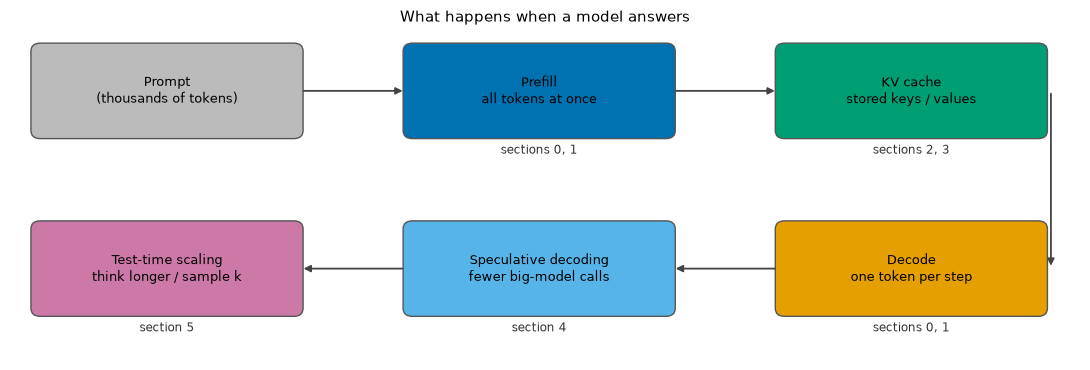

In [3]:
flow(["Prompt\n(thousands of tokens)", "Prefill\nall tokens at once", "KV cache\nstored keys / values", "Decode\none token per step",
      "Speculative decoding\nfewer big-model calls", "Test-time scaling\nthink longer / sample k"],
     notes=["", "sections 0, 1", "sections 2, 3", "sections 0, 1", "section 4", "section 5"],
     colors=[OI["grey"], OI["blue"], OI["green"], OI["orange"], OI["sky"], OI["pink"]], ncol=3, figw=11,
     title="What happens when a model answers")

**그림에서 볼 것**
- 모델이 답할 때는 먼저 프롬프트 전체를 한 번에 읽고(prefill), 그다음 토큰을 하나씩 씁니다(decode). 그 사이를 잇는 것이 KV 캐시입니다 [1, 120–133쪽].
- 아래 줄 두 상자는 decode를 빠르게 하거나(speculative decoding), decode를 일부러 더 많이 써서 정답률을 올리는 방법(test-time scaling)입니다.

## 0. 먼저 알아 둘 것: GPU는 "읽기"와 "계산"을 따로 한다

**한 줄 정의**: GPU에는 숫자를 저장하는 **메모리**(HBM)와 계산하는 **코어**가 있고, 둘 사이를 숫자가 지나가는 속도(**메모리 대역폭**, GB/s)에 한계가 있습니다 [1, 121–122쪽].

**왜 필요한가**: 계산이 아무리 빨라도 숫자를 메모리에서 읽어 오는 속도보다 빨리 끝낼 수는 없습니다. 어느 쪽이 병목인지에 따라 속도를 올리는 방법이 다릅니다.

**먼저 낱말 하나**: **bf16**(bfloat16)은 숫자 하나를 16비트, 즉 2바이트로 저장하는 형식입니다. 보통 쓰는 32비트(4바이트) 실수보다 정밀도는 낮지만 메모리를 절반만 씁니다. 이 노트북의 모델 가중치는 bf16으로 올립니다(아래 셀에서 `element_size() == 2`로 확인).

**숫자로 따라가기**: 이 실습의 GPU(A100 80GB PCIe)는 bf16 계산이 초당 312조 번(312 TFLOP/s), 메모리 대역폭이 초당 1,935 GB입니다 [2]. Qwen3-1.7B로 토큰 **하나**를 만들 때를 계산해 봅니다.

| | 양 | 걸리는 시간 |
|---|---|---|
| 가중치 전부 한 번 읽기 | 약 3.4 GB | 3.4 GB ÷ 1,935 GB/s ≈ 1.8 ms |
| 계산 | 파라미터당 곱하기 1번 + 더하기 1번 = 약 2 × 17억 FLOP | 3.4 × 10⁹ ÷ 312 × 10¹² ≈ 0.011 ms |

토큰 하나를 만들 때는 읽기가 계산보다 100배 넘게 오래 걸립니다. ("파라미터당 2 FLOP"은 행렬 곱 $y = Wx$에서 가중치 하나마다 곱셈과 덧셈을 한 번씩 하는 것을 센 근사입니다. 어텐션 점수 계산은 뺐습니다.)

GPU: NVIDIA A100 80GB PCIe, 가중치 3.44 GB, 파라미터 1.72B


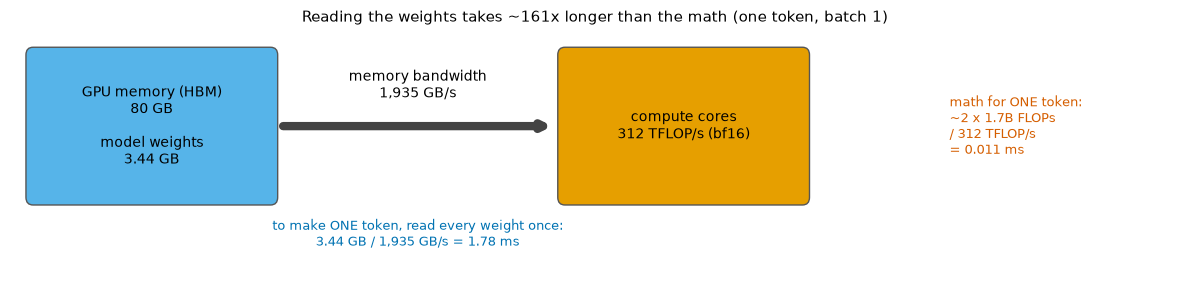

In [4]:
QWEN = "Qwen/Qwen3-1.7B"
qtok = AutoTokenizer.from_pretrained(QWEN)
qwen = AutoModelForCausalLM.from_pretrained(QWEN, dtype=torch.bfloat16 if device == "cuda" else torch.float32).to(device).eval()
weight_bytes = sum(p.numel() * p.element_size() for p in qwen.parameters())
n_params = sum(p.numel() for p in qwen.parameters())
gpu = torch.cuda.get_device_name() if device == "cuda" else "cpu"
PEAK_TFLOPS = 312                                    # A100 bf16 dense [2]
BW_GBS = 1935 if "PCIe" in gpu else 2039             # A100 80GB PCIe / SXM [2]
print(f"GPU: {gpu}, 가중치 {weight_bytes / 1e9:.2f} GB, 파라미터 {n_params / 1e9:.2f}B")
assert torch.tensor([], dtype=torch.bfloat16).element_size() == 2       # bf16 = 숫자 하나에 2바이트
draw_gpu(weight_bytes / 1e9, BW_GBS, PEAK_TFLOPS, n_params / 1e9)

**그림에서 볼 것**
- 가운데 굵은 화살표가 메모리 대역폭입니다. 파란 글씨(읽기 시간)가 빨간 글씨(계산 시간)보다 훨씬 깁니다.
- 그래서 토큰을 하나씩 만드는 decode의 속도는 "얼마나 빨리 계산하나"가 아니라 "얼마나 빨리 읽나"에 걸립니다(memory-bound) [1, 134쪽].
- 이 그림은 사양표 숫자로 계산한 **이론값**입니다. 실제 측정은 아래 1절에서 합니다.

### 산술 강도와 roofline

**한 줄 정의**: **산술 강도**(arithmetic intensity)는 "읽어 온 1바이트로 계산을 몇 번 하는가"(FLOP/byte)입니다. **roofline**은 산술 강도에 따라 낼 수 있는 최대 속도를 그린 그림입니다 [3][4].

**왜 필요한가**: 산술 강도가 낮으면 읽기에 막히고, 높으면 계산에 막힙니다. 둘의 경계(ridge)는 $312 \text{ TFLOP/s} \div 1{,}935 \text{ GB/s} \approx 161$ FLOP/byte입니다.

**숫자로 따라가기** (어텐션과 KV 캐시 읽기는 뺀 근사)

| 상황 | 계산 | 읽기 | 산술 강도 |
|---|---|---|---|
| decode, 토큰 1개 | 2N FLOP | 가중치 2N 바이트(bf16) | 약 1 |
| prefill, 토큰 T개 | 2N × T FLOP | 가중치 2N 바이트(한 번만 읽음) | 약 T |

가중치를 한 번 읽어 토큰 T개에 같이 쓰면 산술 강도가 T배가 됩니다. 그래서 prefill은 roofline의 오른쪽(계산에 막힘), decode는 왼쪽 끝(읽기에 막힘)에 놓입니다 [1, 134쪽].

## 1. prefill과 decode를 재 보기 (슬라이드 120–123쪽)

**한 줄 정의**: **prefill**은 프롬프트 토큰 전부를 한 번에 계산하는 단계, **decode**는 그다음 토큰을 하나씩 만드는 단계입니다 [1, 120쪽, 123쪽].

**왜 필요한가**: 두 단계는 막히는 곳이 달라서 속도가 크게 다릅니다. 에이전트의 비용과 지연 시간을 예측하려면 이 차이를 알아야 합니다.

**숫자로 따라가기**: Qwen3-1.7B로 길이별 prefill 시간과, 토큰 하나당 decode 시간을 잽니다.

In [5]:
@torch.no_grad()
def time_prefill(n):
    ids = torch.randint(1000, 30000, (1, n), device=device)
    qwen(ids); sync()
    t0 = time.perf_counter(); qwen(ids); sync()
    return time.perf_counter() - t0

@torch.no_grad()
def time_decode(n_prompt=512, n_new=64):
    ids = torch.randint(1000, 30000, (1, n_prompt), device=device)
    out = qwen(ids, use_cache=True)
    cache, nxt = out.past_key_values, out.logits[:, -1:].argmax(-1)
    sync(); t0 = time.perf_counter()
    for _ in range(n_new):
        out = qwen(nxt, past_key_values=cache, use_cache=True)
        cache, nxt = out.past_key_values, out.logits[:, -1:].argmax(-1)
    sync()
    return (time.perf_counter() - t0) / n_new

lens = [128, 512, 2048, 8192] if device == "cuda" else [32, 128]
pre = pd.DataFrame({"prompt tokens": lens, "prefill time (s)": [time_prefill(n) for n in lens]})
pre["prefill tokens/s"] = pre["prompt tokens"] / pre["prefill time (s)"]
pre["achieved TFLOP/s"] = 2 * n_params * pre["prompt tokens"] / pre["prefill time (s)"] / 1e12   # 어텐션 계산은 뺀 근사
cfg = qwen.config
d_attn = cfg.num_attention_heads * (getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads)
attn_flops = 2 * cfg.num_hidden_layers * pre["prompt tokens"] ** 2 * d_attn          # QK^T 와 AV, causal 이라 절반만
pre["attention FLOPs left out (%)"] = 100 * attn_flops / (attn_flops + 2 * n_params * pre["prompt tokens"])
dec = time_decode() if device == "cuda" else time_decode(32, 8)
dec_tflops = 2 * n_params / dec / 1e12
print(f"decode: 토큰 하나에 {dec * 1e3:.1f} ms  →  {1 / dec:.0f} tokens/s, 가중치 읽는 속도 ≈ {weight_bytes / dec / 1e9:.0f} GB/s")
display(pre.round(3))
if device == "cuda":
    assert pre["prefill tokens/s"].max() > 20 / dec       # prefill 이 토큰당 20배 넘게 빠르다

decode: 토큰 하나에 11.9 ms  →  84 tokens/s, 가중치 읽는 속도 ≈ 288 GB/s


,prompt tokens,prefill time (s),prefill tokens/s,achieved TFLOP/s,attention FLOPs left out (%)
0,128,0.013,10041.051,34.553,0.425
1,512,0.020,26160.581,90.022,1.678
2,2048,0.062,33189.937,114.212,6.390
3,8192,0.255,32145.058,110.616,21.447


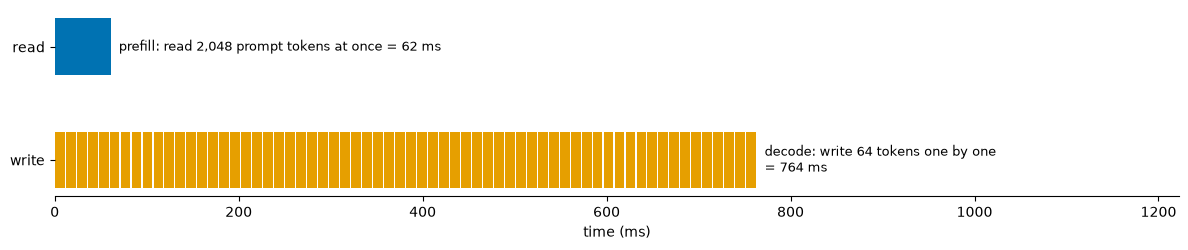

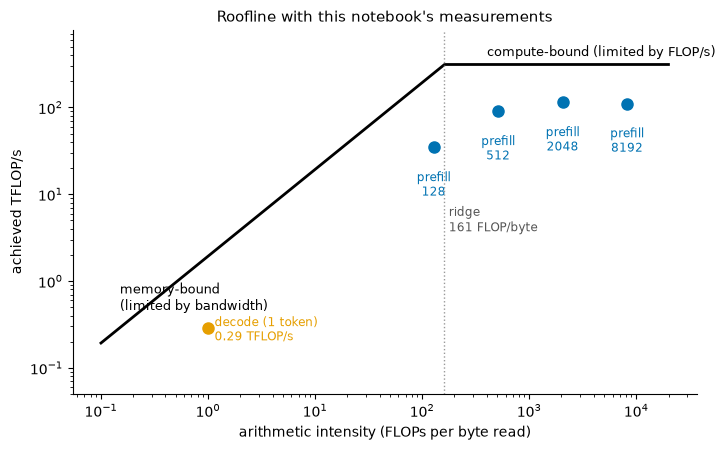

In [6]:
i2048 = lens.index(2048) if 2048 in lens else -1
draw_timeline(lens[i2048], pre["prefill time (s)"].iloc[i2048] * 1e3, 64, dec * 1e3)
draw_roofline(PEAK_TFLOPS, BW_GBS,
              [(f"decode (1 token)\n{dec_tflops:.2f} TFLOP/s", 1.0, dec_tflops, OI["orange"])] +
              [(f"prefill {n}", n, tf, OI["blue"]) for n, tf in zip(pre["prompt tokens"], pre["achieved TFLOP/s"])])

**그림에서 볼 것**
- 시간 막대(이 노트북의 결과): 프롬프트 2,048 토큰을 **읽는** 시간보다, 64 토큰을 **쓰는** 시간이 훨씬 깁니다. 주황 칸 하나가 토큰 하나입니다.
- roofline: 파란 점(prefill)은 길이가 길수록 오른쪽 위로 올라가지만, 계산 지붕(312 TFLOP/s)에 닿지 못하고 그 3분의 1 남짓에서 멈춥니다(위 표의 achieved TFLOP/s). 주황 점(decode)은 왼쪽 아래, 대역폭 지붕보다도 한참 아래에 있습니다.
- 읽을 때 조심할 점 두 가지. (1) 세로축 값은 어텐션 계산을 빼고 센 것이라, 어텐션 몫이 큰 긴 프롬프트일수록 실제보다 낮게 나옵니다(표의 마지막 열: 전체 계산 중 빠진 몫이 8,192 토큰에서 약 21%, 2,048 토큰에서 약 6%. 바꿔 말하면 8,192 토큰의 값은 실제보다 약 27%, 2,048 토큰은 약 7% 낮게 나옵니다). 8,192가 2,048보다 낮게 찍히는 이유 중 일부가 이것입니다. (2) 가로축은 잰 값이 아니라 "산술 강도 ≈ T"라는 이론값입니다.
- decode 점이 대역폭 지붕보다 낮은 것은 이 노트북의 해석으로는, 작은 모델에서 토큰 하나마다 파이썬이 작은 GPU 명령 수백 개를 하나씩 보내는 시간(launch overhead)이 더 크기 때문입니다. 여러 GPU 명령을 CPU 한 번으로 보내는 CUDA Graphs [5]를 vLLM 같은 추론 서버가 지연을 줄이려고 씁니다 [6].
- 그래서 긴 답을 쓰는 것이 긴 글을 읽는 것보다 훨씬 오래 걸립니다. 예를 들어 Anthropic API 가격표에서도 출력 토큰 단가가 입력 토큰 단가의 5배입니다 [7].

**직접 바꿔 보기**: `time_decode(n_prompt=8192)`로 프롬프트를 길게 하면 decode 한 걸음이 느려지는지 보세요(KV 캐시를 더 많이 읽어야 함).

## 2. KV 캐시 (슬라이드 124–133쪽)

**한 줄 정의**: 앞 토큰들의 Key와 Value를 저장해 두고, 새 토큰을 만들 때 다시 계산하지 않는 저장소입니다 [1, 133쪽].

**왜 필요한가**: causal mask 때문에 앞 토큰은 뒤 토큰을 보지 않습니다(A2). 그래서 뒤에 토큰이 붙어도 앞 토큰의 K, V는 **변하지 않습니다**. 이미 계산한 것을 다시 계산하는 것은 낭비입니다.

**숫자로 따라가기**: 프롬프트 6토큰에 새 토큰 6개를 쓴다고 합니다. 새 토큰 6개를 만드는 데 걸음 6번이 필요합니다(첫 걸음이 prefill, 마지막에 만든 토큰은 다시 넣지 않음).

- 캐시 없음: 걸음마다 지금까지의 토큰을 전부 다시 계산 → 6 + 7 + 8 + 9 + 10 + 11 = 51번
- 캐시 있음: 처음에 6개, 이후 걸음마다 바로 전에 만든 토큰 1개 → 6 + 5 = 11번

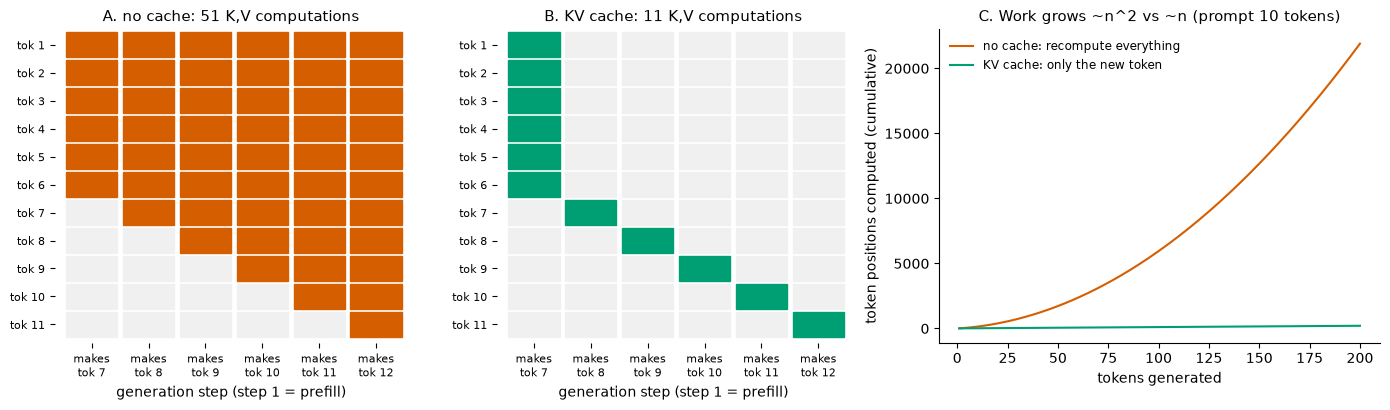

In [7]:
draw_kv_work()

**그림에서 볼 것**
- A, B: 가로가 생성 걸음(아래 글자는 그 걸음이 만드는 토큰), 세로가 입력 토큰입니다. 칠한 칸이 그 걸음에 K, V를 계산한 토큰입니다. A는 삼각형으로 쌓여 51칸, B는 첫 열과 대각선 한 줄로 11칸입니다.
- C: 길이 200을 쓰면 캐시가 없을 때 계산량은 길이의 제곱으로, 있을 때는 길이에 비례해 늘어납니다.
- 대신 캐시는 **메모리**를 씁니다. 저장한 K, V는 토큰 수에 비례해 쌓입니다(3절).

**직접 짜 보기**: A2의 `gpt2_forward`에 캐시를 붙입니다. 바뀐 곳은 세 군데입니다: (1) 위치 임베딩을 이어지는 위치부터 꺼냄, (2) 새 K, V를 캐시 뒤에 붙임, (3) mask를 "새 토큰 × 전체 토큰" 크기로 만듦.

In [8]:
gtok = AutoTokenizer.from_pretrained("openai-community/gpt2")
g2 = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device).eval()
sd = {k: v.detach() for k, v in g2.state_dict().items()}
NL, NH, D = g2.config.n_layer, g2.config.n_head, g2.config.n_embd
HD = D // NH

def ln(x, w, b):
    return F.layer_norm(x, (D,), w, b, eps=1e-5)

def gpt2_step(ids_new, cache=None):
    """ids_new: 이번에 넣을 토큰들. cache: 층마다 (K, V) 또는 None. 돌려주는 것: logits, 새 cache"""
    past = 0 if cache is None else cache[0][0].shape[1]
    T = len(ids_new)
    x = sd["transformer.wte.weight"][ids_new] + sd["transformer.wpe.weight"][past:past + T]   # (1) 이어지는 위치
    new_cache = []
    for i in range(NL):
        p = f"transformer.h.{i}."
        h = ln(x, sd[p + "ln_1.weight"], sd[p + "ln_1.bias"])
        q, k, v = (h @ sd[p + "attn.c_attn.weight"] + sd[p + "attn.c_attn.bias"]).split(D, -1)
        q, k, v = (t.view(T, NH, HD).transpose(0, 1) for t in (q, k, v))
        if cache is not None:                                                              # (2) 캐시 뒤에 붙임
            k = torch.cat([cache[i][0], k], 1)
            v = torch.cat([cache[i][1], v], 1)
        new_cache.append((k, v))
        s = q @ k.transpose(-2, -1) / math.sqrt(HD)
        mask = torch.triu(torch.ones(T, past + T, dtype=torch.bool, device=x.device), diagonal=past + 1)   # (3)
        y = torch.softmax(s.masked_fill(mask, float("-inf")), -1) @ v
        x = x + y.transpose(0, 1).reshape(T, D) @ sd[p + "attn.c_proj.weight"] + sd[p + "attn.c_proj.bias"]
        h = ln(x, sd[p + "ln_2.weight"], sd[p + "ln_2.bias"])
        h = F.gelu(h @ sd[p + "mlp.c_fc.weight"] + sd[p + "mlp.c_fc.bias"], approximate="tanh")
        x = x + h @ sd[p + "mlp.c_proj.weight"] + sd[p + "mlp.c_proj.bias"]
    x = ln(x, sd["transformer.ln_f.weight"], sd["transformer.ln_f.bias"])
    return x @ sd["transformer.wte.weight"].T, new_cache

@torch.no_grad()
def greedy_no_cache(ids, n):
    for _ in range(n):
        logits, _ = gpt2_step(ids)                    # 매번 전체를 다시 계산
        ids = torch.cat([ids, logits[-1].argmax().view(1)])
    return ids

@torch.no_grad()
def greedy_with_cache(ids, n):
    logits, cache = gpt2_step(ids)                    # prefill
    for _ in range(n):
        nxt = logits[-1].argmax().view(1)
        ids = torch.cat([ids, nxt])
        logits, cache = gpt2_step(nxt, cache)         # 새 토큰 하나만 계산
    return ids

prompt_ids = gtok("The class was about how agents work, and", return_tensors="pt").input_ids[0].to(device)
N_NEW = 200
sync(); t0 = time.perf_counter(); a = greedy_no_cache(prompt_ids, N_NEW); sync(); t_no = time.perf_counter() - t0
sync(); t0 = time.perf_counter(); b = greedy_with_cache(prompt_ids, N_NEW); sync(); t_kv = time.perf_counter() - t0
with torch.no_grad():
    hf = g2.generate(prompt_ids[None], max_new_tokens=N_NEW, do_sample=False, pad_token_id=gtok.eos_token_id)[0]
print(f"캐시 없음 {t_no:.2f}s, 캐시 있음 {t_kv:.2f}s  ({t_no / t_kv:.1f}배)")
print(gtok.decode(b[:40]))
assert torch.equal(a, b)          # 캐시가 있어도 같은 토큰이 나온다
assert torch.equal(b, hf)         # Hugging Face(내부적으로 KV 캐시 사용)와도 같다

캐시 없음 0.83s, 캐시 있음 0.45s  (1.9배)
The class was about how agents work, and how they can be trusted.

"We're not going to be able to do that," he said. "We're going to have to do


이 노트북의 결과: 캐시가 있어도 없어도 200 토큰이 **똑같이** 나옵니다. 속도 차이가 C 그림의 계산량 차이만큼 크지 않습니다. 이 노트북의 해석으로는, 이 작은 모델에서는 GPU가 긴 입력도 거의 같은 시간에 처리하고 걸음마다 드는 고정 비용(1절의 launch overhead)이 더 크기 때문입니다.

## 3. KV 캐시는 메모리를 얼마나 먹나

**한 줄 정의**: 토큰 하나당 캐시 크기는 "K와 V(2) × 층 수 × KV head 수 × head 차원 × 숫자 하나의 바이트"입니다.

**왜 필요한가**: 캐시는 대화 길이에 비례해 커지고, 요청마다 따로 필요합니다. KV 캐시 메모리가 크고 들쭉날쭉해서 한 GPU가 동시에 처리할 수 있는 요청 수를 제한한다는 것이 vLLM 논문의 출발점입니다 [8].

**숫자로 따라가기**: Qwen3-8B는 층 36개, query head 32개, KV head 8개입니다 [9]. head 차원은 128입니다 [18]. bf16은 숫자 하나에 2바이트입니다(0절).

$$2 \times 36 \times 8 \times 128 \times 2 = 147{,}456 \text{ 바이트} = 144 \text{ KB / 토큰}$$

32,768 토큰 대화 하나면 $144 \text{ KB} \times 32{,}768 \approx 4.8$ GB입니다. 이런 대화 4개면 모델 가중치(약 16 GB)보다 캐시가 커집니다.

**GQA**(grouped-query attention)는 query head 여러 개가 K, V head 하나를 나눠 쓰게 해서 캐시를 줄입니다 [10]. Qwen3-8B는 query head 4개가 KV head 하나를 나눠 쓰므로 캐시가 4분의 1입니다.

먼저 Qwen3-1.7B로 공식과 실제 캐시 크기가 같은지 확인합니다.

In [9]:
def kv_bytes_per_token(cfg, nbytes=2):
    n_kv = getattr(cfg, "num_key_value_heads", None) or cfg.num_attention_heads
    hd = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
    return 2 * cfg.num_hidden_layers * n_kv * hd * nbytes

def cache_tensors(cache):
    if hasattr(cache, "layers"):
        return [t for l in cache.layers for t in (l.keys, l.values)]
    return list(cache.key_cache) + list(cache.value_cache)

n = 1000
with torch.no_grad():
    cache = qwen(torch.randint(1000, 30000, (1, n), device=device), use_cache=True).past_key_values
real = sum(t.numel() * t.element_size() for t in cache_tensors(cache))
formula = kv_bytes_per_token(qwen.config, next(qwen.parameters()).element_size()) * n
print(f"공식 {formula:,} bytes / 실제 {real:,} bytes")
assert real == formula

공식 114,688,000 bytes / 실제 114,688,000 bytes


,model,KB per token (bf16),GB at 32k tokens,GB at 32k without GQA
0,gpt2,36.0,1.21,1.21
1,Qwen3-1.7B,112.0,3.76,7.52
2,Qwen3-8B,144.0,4.83,19.33
3,Qwen3-32B,256.0,8.59,68.72


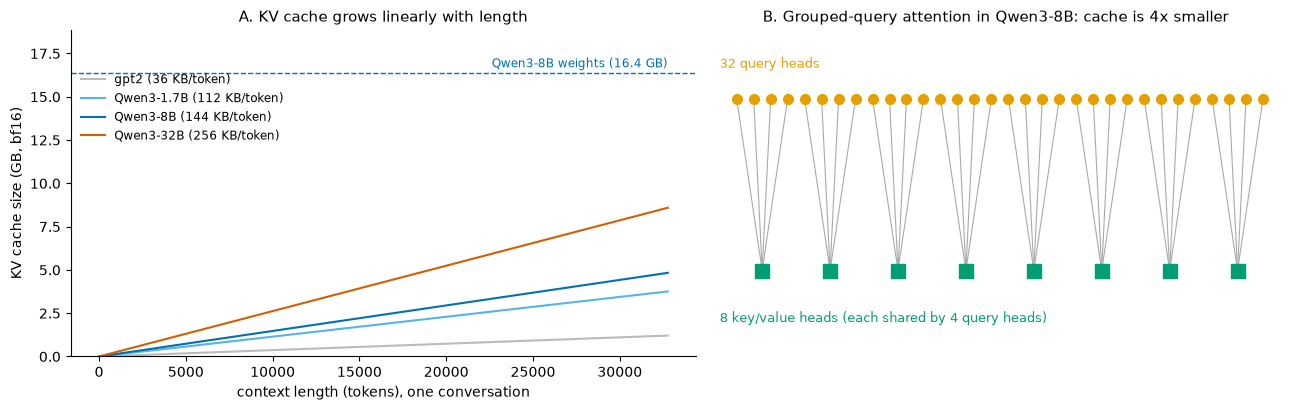

In [10]:
rows = []
for name in ["openai-community/gpt2", "Qwen/Qwen3-1.7B", "Qwen/Qwen3-8B", "Qwen/Qwen3-32B"]:
    c = AutoConfig.from_pretrained(name)
    per_tok = kv_bytes_per_token(c)
    no_gqa = 2 * c.num_hidden_layers * c.num_attention_heads * (getattr(c, "head_dim", None) or c.hidden_size // c.num_attention_heads) * 2
    rows.append({"model": name.split("/")[1], "KB per token (bf16)": per_tok / 1024,
                 "GB at 32k tokens": per_tok * 32768 / 1e9, "GB at 32k without GQA": no_gqa * 32768 / 1e9})
kv_table = pd.DataFrame(rows)
display(kv_table.round(2))
c8 = AutoConfig.from_pretrained("Qwen/Qwen3-8B")
assert kv_bytes_per_token(c8) == 147456                      # 위 손 계산과 같다
draw_kv_memory(list(zip(kv_table["model"], kv_table["KB per token (bf16)"])), 8.2e9 * 2 / 1e9,
               n_q=c8.num_attention_heads, n_kv=c8.num_key_value_heads)

**그림에서 볼 것**
- A: 캐시는 길이에 정비례해 늘어납니다. 파란 점선은 Qwen3-8B 가중치 크기(82억 파라미터 × 2바이트 ≈ 16.4 GB [9])입니다. 32k 대화 몇 개면 캐시가 가중치를 넘습니다.
- B: 주황 점 32개(query head)가 초록 네모 8개(KV head)를 4개씩 나눠 씁니다. 캐시에는 초록 네모만 저장됩니다.
- 표의 마지막 열은 GQA가 없었을 때의 크기입니다. Qwen3-32B는 32k 대화 하나에 약 69 GB가 필요했을 것입니다(이 노트북의 계산).

## 4. speculative decoding (슬라이드 136–137쪽)

**한 줄 정의**: 작은 모델(draft)이 다음 토큰 몇 개를 먼저 쓰고, 큰 모델(target)이 그것을 **한 번에** 검사해 맞는 만큼 받아들이는 방법입니다 [11][12].

**왜 필요한가**: decode는 토큰 하나마다 큰 모델 가중치를 전부 읽어서 느립니다(0절). 그런데 큰 모델이 짧은 이어쓰기 여러 토큰을 한꺼번에 검사하는 시간은 토큰 하나를 만드는 시간과 비슷합니다 [12]. 검사는 prefill처럼 여러 토큰을 같이 처리하기 때문입니다.

**숫자로 따라가기**: draft가 4개를 쓰고 큰 모델이 앞 2개에 동의하면, 큰 모델 호출 한 번으로 토큰 3개(동의한 2개 + 큰 모델이 고친 1개)를 얻습니다. 혼자 쓰면 호출 3번이 필요합니다.

1. 작은 모델(GPT-2, 1.2억)이 다음 토큰 $\gamma=4$개를 씁니다.
2. 큰 모델(GPT-2 large, 7.7억)이 그 4개를 한 번에 읽고, 자리마다 "나라면 무엇을 썼을지"를 냅니다.
3. 앞에서부터 일치하는 만큼 받아들이고, 처음 어긋나는 자리에는 큰 모델의 토큰을 씁니다.

greedy끼리라면 결과는 큰 모델 혼자 쓴 것과 **정확히 같습니다**. 샘플링에서도 큰 모델의 분포를 바꾸지 않도록 받아들이는 규칙이 있습니다 [11][12].

큰 모델 호출: 혼자 100번 → speculative 29번,  draft 토큰 채택률 64%
시간: 혼자 1.46s → speculative 0.84s


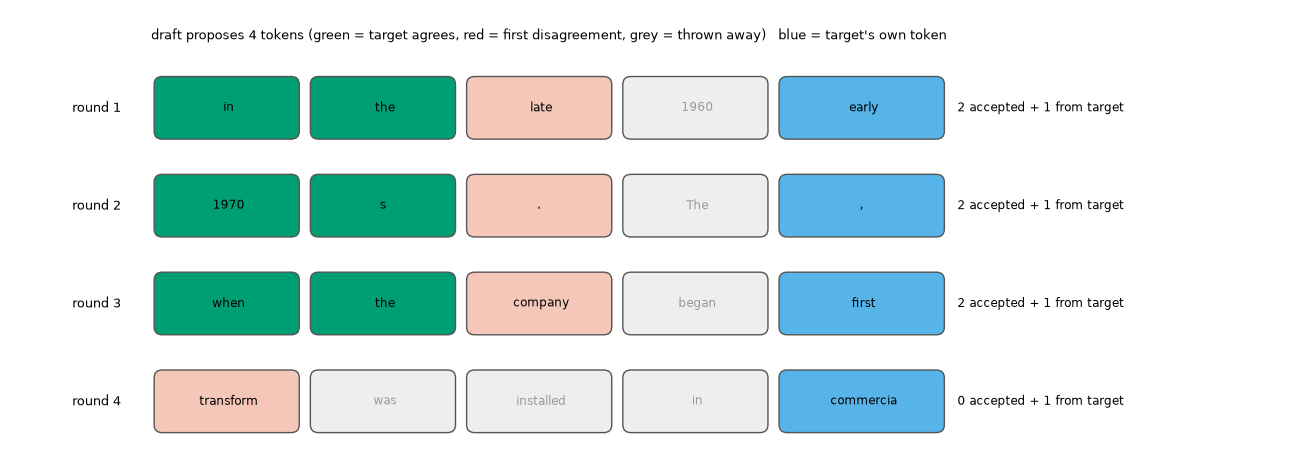

In [11]:
draft = AutoModelForCausalLM.from_pretrained("openai-community/gpt2").to(device).eval()
target = AutoModelForCausalLM.from_pretrained("openai-community/gpt2-large").to(device).eval()

@torch.no_grad()
def target_greedy(ids, n):
    calls = 0
    for _ in range(n):
        ids = torch.cat([ids, target(ids[None]).logits[0, -1].argmax().view(1)]); calls += 1
    return ids, calls

@torch.no_grad()
def speculative(ids, n, gamma=4):
    start, calls, proposed, accepted, trace = len(ids), 0, 0, 0, []
    while len(ids) - start < n:
        d = ids
        for _ in range(gamma):                                   # 1. draft 가 gamma 개를 쓴다
            d = torch.cat([d, draft(d[None]).logits[0, -1].argmax().view(1)])
        guess = d[len(ids):]
        want = target(d[None]).logits[0, len(ids) - 1:].argmax(-1)   # 2. target 이 한 번에 검사 (gamma+1 자리)
        calls += 1
        k = 0
        while k < gamma and guess[k] == want[k]:                 # 3. 일치하는 만큼 받아들임
            k += 1
        trace.append(([gtok.decode(t) for t in guess], k, gtok.decode(want[k])))
        ids = torch.cat([ids, guess[:k], want[k:k + 1]])         #    + target 의 토큰 하나
        proposed += gamma; accepted += k
    return ids[:start + n], calls, accepted / proposed, trace

p_ids = gtok("The history of the transformer architecture began", return_tensors="pt").input_ids[0].to(device)
N_SPEC = 100
sync(); t0 = time.perf_counter(); ref, ref_calls = target_greedy(p_ids, N_SPEC); sync(); t_ref = time.perf_counter() - t0
sync(); t0 = time.perf_counter(); spec, spec_calls, acc_rate, trace = speculative(p_ids, N_SPEC); sync(); t_spec = time.perf_counter() - t0
assert torch.equal(ref, spec)       # 큰 모델 혼자 쓴 것과 똑같다
print(f"큰 모델 호출: 혼자 {ref_calls}번 → speculative {spec_calls}번,  draft 토큰 채택률 {acc_rate:.0%}")
print(f"시간: 혼자 {t_ref:.2f}s → speculative {t_spec:.2f}s")
draw_spec(trace)

**그림에서 볼 것** (이 노트북의 실제 처음 네 라운드)
- 초록 칸은 큰 모델이 동의해 받아들인 draft 토큰, 빨간 칸은 처음 어긋난 자리, 회색은 그 뒤라 버린 토큰입니다. 파란 칸은 큰 모델이 직접 고른 토큰입니다.
- 라운드마다 큰 모델 호출은 한 번입니다. 초록이 많을수록 호출 한 번에 얻는 토큰이 많습니다.
- 이 구현은 두 모델 다 캐시 없이 매번 전체를 다시 계산하는 단순한 방식이라, 시간 차이는 실제보다 작게 나옵니다. 핵심 숫자는 **큰 모델 호출 횟수**입니다. 슬라이드 137쪽처럼 draft가 잘 맞히는 분야(예측하기 쉬운 글, 코드)일수록 효과가 큽니다 [1, 137쪽].

## 5. test-time scaling: 추론 때 계산을 더 쓰기 (슬라이드 138–148쪽)

**한 줄 정의**: 모델을 키우지 않고, 답을 만들 때 계산(토큰)을 더 써서 정답률을 올리는 방법들입니다 [1, 138쪽].

**왜 필요한가**: 같은 모델이라도 바로 답하게 할 때와 풀이를 쓰게 하거나 여러 번 시켜 볼 때 정답률이 다릅니다. 대신 decode 토큰이 늘어 시간과 비용이 늡니다(1절).

두 갈래가 있습니다.

- **생각하게 하기**: 답 전에 풀이를 쓰게 합니다(chain of thought [13]). 추론 모델은 이것을 학습으로 익혔고, 생각의 양을 조절하는 손잡이를 줍니다. Qwen3는 생각 모드와 안 생각 모드를 한 모델에 넣었고 [14], `enable_thinking`으로 켜고 끕니다 [9]. GPT-OSS는 시스템 프롬프트에 `Reasoning: low/medium/high`를 씁니다 [1, 143쪽].
- **여러 번 뽑기**: 같은 문제에 답을 $k$개 뽑습니다.
  - 채점기(verifier)가 있으면 하나라도 맞으면 됩니다 → **pass@k** [15][16]
  - 채점기가 없으면 가장 많이 나온 답을 고릅니다 → **다수결**(self-consistency) [17]

**숫자로 따라가기**: 16개를 뽑아 정답이 5개, 오답 "33"이 7개, 나머지가 제각각이면, pass@16은 성공(정답이 하나라도 있음)이고 다수결은 실패("33"이 가장 많음)입니다. 채점기가 있으냐에 따라 같은 16개로 결과가 달라집니다.

정답을 프로그램으로 확인할 수 있는 여러 단계 계산 문제를 만들어 실험합니다.

In [12]:
def make_problem(rng):
    a, b, c, d, e, f = rng.randint(120, 480), rng.randint(15, 95), rng.randint(15, 95), rng.randint(3, 9), rng.randint(12, 48), rng.randint(2, 6)
    q = (f"A lab starts with {a} sample tubes. On Monday it uses {b} tubes and on Tuesday it uses {c} tubes. "
         f"Then it receives {d} boxes with {e} tubes in each box. Finally it splits all tubes equally into {f} racks, "
         f"putting the leftover tubes in the freezer. How many tubes go into each rack?")
    return q, (a - b - c + d * e) // f

rng = random.Random(1)
problems = [make_problem(rng) for _ in range(40)]
print(problems[0])

def chat(q, thinking):
    msg = [{"role": "user", "content": q + "\nEnd your reply with 'Answer: <number>'."}]
    return qtok.apply_chat_template(msg, tokenize=False, add_generation_prompt=True, enable_thinking=thinking)

def parse(text, thinking=False):
    """마지막 'Answer: 숫자' 를 읽는다. 생각을 켰으면 </think> 뒤(최종 답)에서만 읽고, 생각이 끝나지 않고 잘렸으면 None(오답)."""
    if thinking:
        if "</think>" not in text:
            return None
        text = text.split("</think>")[-1]
    m = re.findall(r"Answer:\s*\**\s*(-?\d[\d,]*)", text)
    return int(m[-1].replace(",", "")) if m else None

qtok.padding_side = "left"

@torch.no_grad()
def sample_answers(qs, thinking, k, max_new, temperature, top_p, bs_prompts=20):
    outs, ntoks = [], []
    for i in range(0, len(qs), bs_prompts):
        enc = qtok([chat(q, thinking) for q in qs[i:i + bs_prompts]], return_tensors="pt", padding=True).to(device)
        gen = qwen.generate(**enc, max_new_tokens=max_new, do_sample=True, temperature=temperature, top_p=top_p,
                            num_return_sequences=k, pad_token_id=qtok.pad_token_id)[:, enc.input_ids.shape[1]:]
        outs += qtok.batch_decode(gen, skip_special_tokens=False)     # </think> 표시를 지우지 않으려고 특수 토큰을 남긴다
        ntoks += (gen != qtok.pad_token_id).sum(1).tolist()
    return outs, ntoks

('A lab starts with 188 sample tubes. On Monday it uses 87 tubes and on Tuesday it uses 23 tubes. Then it receives 5 boxes with 19 tubes in each box. Finally it splits all tubes equally into 5 racks, putting the leftover tubes in the freezer. How many tubes go into each rack?', 34)


### 생각 끄고 16번씩 뽑기

In [13]:
K = 16
t0 = time.time()
texts, ntoks = sample_answers([q for q, _ in problems], thinking=False, k=K, max_new=256, temperature=0.7, top_p=0.8)
answers = np.array([parse(t) for t in texts], dtype=object).reshape(len(problems), K)
truth = np.array([ans for _, ans in problems])
correct = np.array([[a == t for a in row] for row, t in zip(answers, truth)])
print(f"{len(texts)}개 답, {time.time() - t0:.0f}초, 답 하나 평균 {np.mean(ntoks):.0f} 토큰")
print(f"답 하나의 정답률: {correct.mean():.2f}")

640개 답, 25초, 답 하나 평균 200 토큰
답 하나의 정답률: 0.49


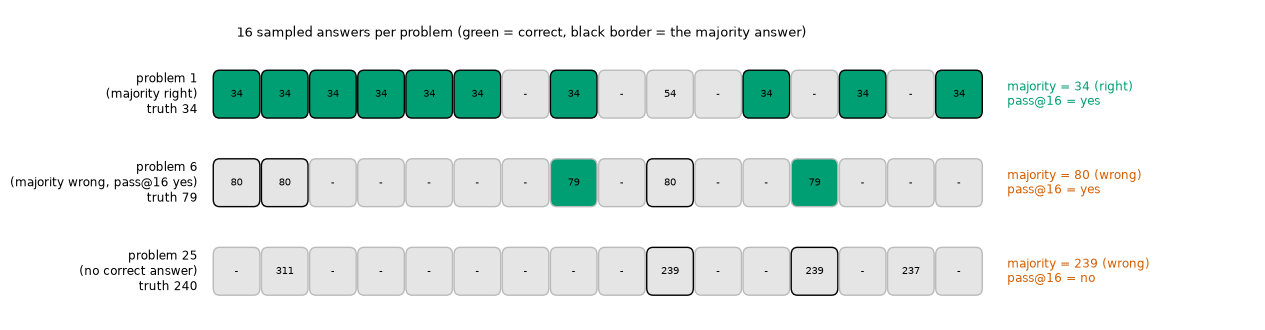

In [14]:
def majority(row):
    votes = Counter(a for a in row if a is not None)
    return votes.most_common(1)[0][0] if votes else None

def pick_examples():
    """그림용으로 서로 다른 경우를 하나씩 고른다: 다수결 성공, 다수결 실패지만 pass@16 성공, 둘 다 실패"""
    kinds = {"majority right": None, "majority wrong, pass@16 yes": None, "no correct answer": None}
    for i, (row, t) in enumerate(zip(answers, truth)):
        m, anyc = majority(row) == t, t in list(row)
        key = "majority right" if m else ("majority wrong, pass@16 yes" if anyc else "no correct answer")
        if kinds[key] is None:
            kinds[key] = i
    return [(f"problem {i + 1}\n({k})", list(answers[i]), truth[i]) for k, i in kinds.items() if i is not None]

draw_votes(pick_examples())

**그림에서 볼 것**
- 한 줄이 한 문제의 답 16개입니다. 초록이 정답, 검은 테두리가 가장 많이 나온 답입니다.
- `-` 칸은 256 토큰 안에 `Answer: <숫자>`를 쓰지 않아 숫자를 읽지 못한 답입니다. 다수결에서는 빼고 셉니다. 생각을 끈 작은 모델은 형식을 자주 놓칩니다(A6의 형식 강제와 이어지는 이야기입니다).
- "majority wrong, pass@16 yes" 줄: 정답이 섞여 있지만 같은 오답이 더 많이 나와 다수결은 틀립니다. 채점기가 있으면 맞힙니다.
- 모델이 **같은 방식으로 일관되게 틀리는** 문제는 아무리 많이 뽑아도 다수결로 고칠 수 없습니다.

,k,pass@k (with verifier),majority vote@k (no verifier)
0,1,0.486,0.491
1,2,0.677,0.656
2,4,0.833,0.780
3,8,0.930,0.857
4,16,0.975,0.900


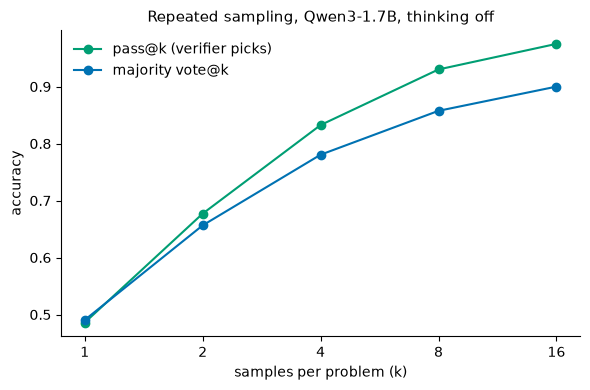

In [15]:
def pass_at_k(n, c, k):
    """n 개 중 c 개가 정답일 때, 무작위로 k 개를 골라 하나라도 정답일 확률 [16]"""
    return 1.0 if n - c < k else 1 - math.comb(n - c, k) / math.comb(n, k)

def majority_at_k(row, t, k, reps=50, seed=0):
    r = random.Random(seed)
    hits = 0
    for _ in range(reps):
        votes = Counter(a for a in r.sample(list(row), k) if a is not None)
        hits += bool(votes) and votes.most_common(1)[0][0] == t
    return hits / reps

ks = [1, 2, 4, 8, 16]
curve = pd.DataFrame({
    "k": ks,
    "pass@k (with verifier)": [np.mean([pass_at_k(K, c.sum(), k) for c in correct]) for k in ks],
    "majority vote@k (no verifier)": [np.mean([majority_at_k(row, t, k) for row, t in zip(answers, truth)]) for k in ks],
})
display(curve.round(3))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(curve["k"], curve["pass@k (with verifier)"], "o-", color=OI["green"], label="pass@k (verifier picks)")
ax.plot(curve["k"], curve["majority vote@k (no verifier)"], "o-", color=OI["blue"], label="majority vote@k")
ax.set_xscale("log", base=2); ax.set_xticks(ks, ks)
ax.set_xlabel("samples per problem (k)"); ax.set_ylabel("accuracy")
ax.set_title("Repeated sampling, Qwen3-1.7B, thinking off")
ax.legend(frameon=False); fig.tight_layout(); plt.show()
assert curve["pass@k (with verifier)"].is_monotonic_increasing
assert curve["pass@k (with verifier)"].iloc[-1] > curve["pass@k (with verifier)"].iloc[0]

**그림에서 볼 것**
- 초록(채점기 있음)은 $k$를 늘릴수록 계속 오릅니다. $k=1$에서는 두 선이 같은 것(답 하나의 정답률)을 재므로 거의 같고, 작은 차이는 뽑기 잡음입니다. $k$가 커지면 파랑(다수결)은 초록보다 낮아지고 차이가 벌어집니다(이 노트북의 결과).
- 채점기가 있는 분야에서는 뽑는 수를 늘릴수록 푼 문제 비율이 계속 늘어나고, 채점기가 없으면 다수결이 수백 개 근처에서 더 오르지 않는다는 보고가 있습니다 [15]. 위 그림은 그 이야기를 16개 규모로 본 것입니다.

### 생각 켜고 한 번씩 뽑기

이번에는 풀이를 쓰게 하고(thinking), 답은 한 번만 뽑습니다. 정답률과 함께 **쓴 토큰 수**(= decode 시간 = 비용)를 비교합니다.

생각 켬 40문제: 정답 32, 숫자는 읽었지만 틀림 0, 최종 답에 형식이 없거나 생각이 안 끝남 8
46초, 2048 토큰에서 잘린 비율 5%, 생각이 끝나지 않은(</think> 없음) 비율 2% (오답으로 셈)


,setting,accuracy,tokens per problem
0,"thinking off, 1 sample",0.49,199.75
1,"thinking off, 16 samples + majority",0.90,3195.98
2,"thinking on, 1 sample",0.80,1297.75


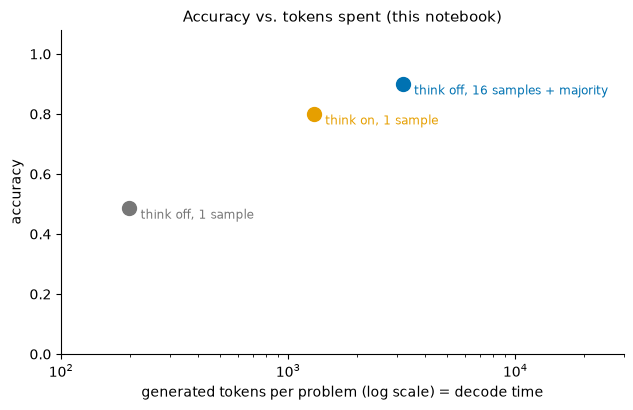

In [16]:
t0 = time.time()
th_texts, th_ntoks = sample_answers([q for q, _ in problems], thinking=True, k=1, max_new=2048, temperature=0.6, top_p=0.95, bs_prompts=40)
th_correct = np.array([parse(t, thinking=True) == ans for t, (_, ans) in zip(th_texts, problems)])
no_end = np.mean(["</think>" not in t for t in th_texts])
th_parsed = [parse(t, thinking=True) for t in th_texts]
print(f"생각 켬 {len(th_texts)}문제: 정답 {int(th_correct.sum())}, 숫자는 읽었지만 틀림 {sum(a is not None and not c for a, c in zip(th_parsed, th_correct))}, "
      f"최종 답에 형식이 없거나 생각이 안 끝남 {sum(a is None for a in th_parsed)}")
cut = np.mean([n >= 2048 for n in th_ntoks])
summary = pd.DataFrame([
    {"setting": "thinking off, 1 sample", "accuracy": correct.mean(), "tokens per problem": np.mean(ntoks)},
    {"setting": "thinking off, 16 samples + majority", "accuracy": curve.iloc[-1, 2], "tokens per problem": np.mean(ntoks) * K},
    {"setting": "thinking on, 1 sample", "accuracy": th_correct.mean(), "tokens per problem": np.mean(th_ntoks)},
])
print(f"{time.time() - t0:.0f}초, 2048 토큰에서 잘린 비율 {cut:.0%}, 생각이 끝나지 않은(</think> 없음) 비율 {no_end:.0%} (오답으로 셈)")
display(summary.round(2))
draw_cost([(s.replace("thinking", "think"), a, t) for s, a, t in summary.itertuples(index=False)])

**그림에서 볼 것**
- 가로는 문제 하나에 쓴 토큰(로그 눈금), 세로는 정답률입니다. 오른쪽으로 갈수록 비싸고, 위로 갈수록 정확합니다.
- 이 노트북의 결과: 생각을 켜면 답 하나에 쓰는 토큰이 크게 늘고, 생각을 끈 답 하나보다 정답률이 크게 오릅니다. 이번 실행에서 생각을 켠 답 하나는 짧은 답 16개의 다수결보다 정답률은 조금 낮았지만, 토큰은 절반도 안 썼습니다(표). 문제 종류가 바뀌면 결과도 바뀔 수 있습니다.
- 생각을 켠 답은 `</think>` 뒤의 최종 답에서만 숫자를 읽고, 생각이 끝나지 않고 잘렸거나 최종 답에 `Answer: <숫자>`가 없으면 오답으로 셉니다. 생각 끈 답도 형식이 없으면 오답으로 세므로 같은 기준입니다. 이번 실행에서 생각을 켠 답의 오답 8개는 모두 숫자가 틀린 것이 아니라 숫자를 읽을 수 없는 경우였습니다(생각이 끝나지 않음 1개, 최종 답에 형식이 없음 7개, 위에 찍힌 내역). 즉 정답률을 깎은 것은 계산이 아니라 형식이었고, 이것이 A6에서 다루는 "출력 형식 강제"가 필요한 이유입니다.
- 에이전트를 만들 때는 단계마다 이 손잡이를 다르게 둘 수 있습니다(예: 쉬운 도구 호출은 생각을 끄고, 계획 세우기는 켬).

**직접 바꿔 보기**: `max_new=2048`을 512로 줄이면 생각이 중간에 잘리는 비율과 정답률이 어떻게 바뀌는지 보세요.

## 연습 문제

1. decode 속도가 메모리 읽기에 막힌다면, 같은 GPU에서 사용자 32명의 decode를 한꺼번에(batch) 하면 토큰당 시간은 어떻게 될까요? roofline의 산술 강도로 설명해 보세요.
2. Qwen3-8B로 100k 토큰 대화를 하려면 KV 캐시만 몇 GB가 필요한가요? (3절의 144 KB/토큰 이용. Qwen3-8B의 기본 컨텍스트는 32,768 토큰이고, YaRN이라는 위치 확장 방법을 켜야 131,072 토큰까지 쓸 수 있습니다 [9].)
3. speculative decoding에서 draft 채택률이 0%면 큰 모델 호출 수는 혼자 쓸 때와 비교해 어떻게 되나요?
4. pass@k는 채점기가 있어야 쓸 수 있습니다. 유전체 분석 에이전트에서 "채점기" 역할을 할 수 있는 것을 하나 생각해 보세요.

<details><summary>답 보기</summary>

1. 가중치를 한 번 읽어 32명 몫의 토큰을 같이 만들므로, 산술 강도가 약 1에서 약 32로 올라가고 토큰당 가중치 읽기 비용이 32분의 1이 됩니다. 서버가 요청을 묶어 처리(batching)하는 이유입니다. 단, 각자의 KV 캐시는 따로 읽어야 하고 메모리도 따로 차지하므로, 대화가 길면 이득이 줄고 동시에 받을 수 있는 요청 수가 캐시 메모리에 막힙니다 [8].
2. 147,456 바이트 × 100,000 ≈ 14.7 GB입니다.
3. 같습니다. 매번 첫 토큰부터 어긋나도 큰 모델이 토큰 하나는 주므로 호출 한 번에 토큰 하나입니다. 다만 draft를 돌린 시간만큼 손해입니다.
4. 예: 생성한 스크립트가 에러 없이 끝나는지, 출력 파일 형식 검사기(VCF 검증), 알려진 양성 대조군 결과가 재현되는지, 단위 테스트.
</details>

## 정리

- GPU는 읽기(대역폭)와 계산(FLOP/s)이 따로 있습니다. 토큰 하나를 만들 때는 가중치를 다 읽어야 해서 읽기가 병목입니다.
- prefill은 계산에, decode는 읽기에 막힙니다. 쓰는 토큰이 읽는 토큰보다 훨씬 비쌉니다.
- KV 캐시는 앞 토큰의 K, V를 저장해 다시 계산하지 않게 합니다. 결과는 같고, 대신 메모리를 길이에 비례해 씁니다. GQA가 그 크기를 줄입니다.
- speculative decoding은 결과를 바꾸지 않고 큰 모델 호출을 줄입니다.
- 추론 때 계산을 더 쓰면(생각하기, 여러 번 뽑기) 정답률이 오릅니다. 채점기가 있으면 효과가 훨씬 큽니다.

## 출처

| 번호 | 출처 | 이 노트북에서 쓴 곳 |
|---|---|---|
| 1 | Diyi Yang, Michael Ryan, John Yang. *LLMs for Builders*, Stanford CS329Z Lecture 2 slides (2026), `data/lecture02.pdf`; [영상](https://youtu.be/Vr1NzH8bT44) | 120–123쪽 prefill/decode, 121–122·134쪽 GPU·roofline, 133쪽 KV 캐시, 136–137쪽 speculative decoding, 138–148쪽 test-time scaling, 143쪽 GPT-OSS 생각 수준 |
| 2 | NVIDIA. [A100 Tensor Core GPU 사양](https://www.nvidia.com/en-us/data-center/a100/) (2026-11-13 확인): BF16 312 TFLOPS(dense), 80GB PCIe 1,935 GB/s, 80GB SXM 2,039 GB/s | 0절 계산, roofline 지붕 |
| 3 | Williams S, Waterman A, Patterson D. Roofline: an insightful visual performance model for multicore architectures. *Commun. ACM* 52:65–76 (2009). [doi:10.1145/1498765.1498785](https://doi.org/10.1145/1498765.1498785) | roofline 모형 |
| 4 | NERSC. [Roofline Performance Model](https://docs.nersc.gov/tools/performance/roofline/) (2026-11-13 확인) | 산술 강도 정의, ridge(대역폭 한계와 계산 한계의 경계) |
| 5 | NVIDIA Technical Blog. [Getting Started with CUDA Graphs](https://developer.nvidia.com/blog/cuda-graphs/) (2019) | 여러 GPU 명령을 CPU 한 번으로 보내 launch overhead를 줄임 |
| 6 | vLLM documentation. [CUDA Graphs](https://docs.vllm.ai/en/latest/design/cuda_graphs.html) (2026-11-13 확인) | 추론 서버가 지연을 줄이려 CUDA Graphs를 씀 |
| 7 | Anthropic. [Pricing](https://platform.claude.com/docs/en/about-claude/pricing) (2026-11-13 확인) | 출력 토큰 단가가 입력 토큰의 5배 |
| 8 | Kwon W, Li Z, Zhuang S, et al. Efficient Memory Management for Large Language Model Serving with PagedAttention. [arXiv:2309.06180](https://arxiv.org/abs/2309.06180) (2023) | 요청마다 KV 캐시가 크고 변해서 batch 크기를 제한함 |
| 9 | Qwen. [Qwen3-8B 모델 카드](https://huggingface.co/Qwen/Qwen3-8B) (2026-11-13 확인) | 8.2B 파라미터, 층 36, query head 32, KV head 8, `enable_thinking`, 기본 컨텍스트 32,768(YaRN으로 131,072) |
| 10 | Ainslie J, Lee-Thorp J, de Jong M, et al. GQA: Training Generalized Multi-Query Transformer Models from Multi-Head Checkpoints. [arXiv:2305.13245](https://arxiv.org/abs/2305.13245) (2023) | GQA: query head 수보다 적은 KV head |
| 11 | Leviathan Y, Kalman M, Matias Y. Fast Inference from Transformers via Speculative Decoding. [arXiv:2211.17192](https://arxiv.org/abs/2211.17192) (2022) | speculative decoding, 출력 분포를 바꾸지 않음 |
| 12 | Chen C, Borgeaud S, Irving G, et al. Accelerating Large Language Model Decoding with Speculative Sampling. [arXiv:2302.01318](https://arxiv.org/abs/2302.01318) (2023) | 짧은 이어쓰기를 한꺼번에 채점하는 시간이 토큰 하나 만드는 시간과 비슷함 |
| 13 | Wei J, Wang X, Schuurmans D, et al. Chain-of-Thought Prompting Elicits Reasoning in Large Language Models. [arXiv:2201.11903](https://arxiv.org/abs/2201.11903) (2022) | chain of thought |
| 14 | Yang A, Li A, Yang B, et al. Qwen3 Technical Report. [arXiv:2505.09388](https://arxiv.org/abs/2505.09388) (2025) | 생각 모드와 안 생각 모드를 한 모델에, 생각 예산 |
| 15 | Brown B, Juravsky J, Ehrlich R, et al. Large Language Monkeys: Scaling Inference Compute with Repeated Sampling. [arXiv:2407.21787](https://arxiv.org/abs/2407.21787) (2024) | 뽑는 수에 따라 푼 문제 비율이 늘고, 채점기 없으면 다수결이 정체됨 |
| 16 | Chen M, Tworek J, Jun H, et al. Evaluating Large Language Models Trained on Code. [arXiv:2107.03374](https://arxiv.org/abs/2107.03374) (2021) | pass@k와 그 추정식(2.1절 식 1) |
| 17 | Wang X, Wei J, Schuurmans D, et al. Self-Consistency Improves Chain of Thought Reasoning in Language Models. [arXiv:2203.11171](https://arxiv.org/abs/2203.11171) (ICLR 2023) | 여러 풀이를 뽑아 가장 일관된 답을 고르는 다수결 |
| 18 | Qwen. [Qwen3-8B config.json](https://huggingface.co/Qwen/Qwen3-8B/blob/main/config.json) (2026-11-13 확인). 이 노트북의 `assert kv_bytes_per_token(c8) == 147456`이 같은 값을 확인 | head 차원 128 |